# Banking Loan Default Prediction
## Exploratory Data Analysis (EDA)

**Project:** Banking Loan Default Prediction

**Dataset:** 100,000 Synthetic Banking Loan Records

**Objective:** Explore borrower characteristics, financial
information, loan attributes and default behaviour.

**Target Variable:** default_flag

In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Locate project dataset
possible_paths = [
    Path.cwd() / "data/raw/banking_loan_default_dataset.csv",
    Path.cwd().parent / "data/raw/banking_loan_default_dataset.csv"
]

DATA_PATH = next(
    (p for p in possible_paths if p.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError("Dataset CSV not found!")

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Dataset path:", DATA_PATH)


Dataset loaded successfully!
Dataset shape: (100000, 29)
Dataset path: c:\Users\Admin\Desktop\Projects\Banking-Loan-Default-Prediction-ML\data\raw\banking_loan_default_dataset.csv


In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

# Project root directory
PROJECT_ROOT = Path.cwd().parent

# Dataset location
DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "banking_loan_default_dataset.csv"
)

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset location:", DATA_PATH)

Dataset loaded successfully!
Dataset location: c:\Users\Admin\Desktop\Projects\Banking-Loan-Default-Prediction-ML\data\raw\banking_loan_default_dataset.csv


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 100000
Number of columns: 29
Dataset shape: (100000, 29)


In [4]:
df.head()

,loan_id,customer_id,application_date,age,gender,marital_status,education_level,employment_type,employment_years,annual_income_lkr,monthly_income_lkr,home_ownership,existing_loans,outstanding_debt_lkr,credit_score,credit_history_years,previous_defaults,delinquencies_last_2yrs,credit_utilization,loan_purpose,loan_amount_lkr,loan_term_months,interest_rate_pct,monthly_emi_lkr,debt_to_income_ratio,has_cosigner,collateral_type,collateral_value_lkr,default_flag
0,LN0000001,CUST0000001,2024-11-25,25,Female,Married,Secondary,Contract,7.00,"1,931,156.07","160,929.67",Own,1,"1,187,880.75",701.00,7.00,0,0,0.67,Vehicle,"515,829.67",60,12.08,"11,495.21",0.49,No,No Collateral,0.00,0
1,LN0000002,CUST0000002,2024-11-09,59,Male,Married,PhD,Salaried,17.80,"1,243,811.73","103,650.98",Mortgage,1,"885,626.75",721.00,8.50,0,0,0.34,Education,"2,439,406.51",12,12.33,"217,115.08",2.54,No,Fixed Deposit,"2,196,095.97",1
2,LN0000003,CUST0000003,2022-09-28,53,Female,Married,Bachelor,Salaried,4.70,"1,395,198.42","116,266.53",Mortgage,0,"143,823.63",761.00,3.80,0,0,0.26,Housing,"345,290.23",36,9.66,"11,086.51",0.15,No,No Collateral,0.00,0
3,LN0000004,CUST0000004,2023-09-15,42,Male,Married,Master,Salaried,2.10,"3,062,216.47","255,184.71",Rent,0,"2,851,426.87",682.00,2.90,0,0,0.61,Housing,"2,138,803.12",84,10.91,"36,520.39",0.49,Yes,No Collateral,0.00,0
4,LN0000005,CUST0000005,2020-01-03,42,Female,Married,Bachelor,Unemployed,13.10,"2,541,211.95","211,767.66",Mortgage,2,"576,942.73",720.00,6.90,0,0,0.24,Debt Consolidation,"2,270,250.55",48,8.93,"56,419.85",0.36,No,No Collateral,0.00,0


In [5]:
df.tail()

,loan_id,customer_id,application_date,age,gender,marital_status,education_level,employment_type,employment_years,annual_income_lkr,monthly_income_lkr,home_ownership,existing_loans,outstanding_debt_lkr,credit_score,credit_history_years,previous_defaults,delinquencies_last_2yrs,credit_utilization,loan_purpose,loan_amount_lkr,loan_term_months,interest_rate_pct,monthly_emi_lkr,debt_to_income_ratio,has_cosigner,collateral_type,collateral_value_lkr,default_flag
99995,LN0099996,CUST0099996,2019-06-23,70,Male,Married,Secondary,Self-employed,NaN,"2,418,649.24","201,554.10",Mortgage,0,"1,497,972.96",714.00,12.10,0,0,0.34,Education,"5,019,350.18",12,10.75,"443,033.39",2.59,Yes,Vehicle,"8,475,780.03",1
99996,LN0099997,CUST0099997,2025-03-24,21,Female,Married,Bachelor,Contract,3.00,"2,722,806.93","226,900.58",Mortgage,0,"1,095,686.70",675.00,3.00,0,0,0.48,Housing,"4,930,289.30",48,11.47,"128,554.15",0.90,No,Property,"4,231,476.57",0
99997,LN0099998,CUST0099998,2020-01-27,49,Male,Single,Master,Business Owner,7.10,"1,829,660.55","152,471.71",Rent,1,"2,175,637.47",524.00,9.70,0,0,0.21,Housing,"2,815,473.48",84,15.02,"54,361.10",0.68,No,Fixed Deposit,"2,325,933.32",1
99998,LN0099999,CUST0099999,2023-09-26,21,Male,Married,Bachelor,Contract,3.00,"889,699.84","74,141.65",Mortgage,1,"311,242.86",664.00,3.00,0,0,0.45,Personal,"1,771,891.93",36,10.13,"57,282.18",0.89,Yes,Property,"1,366,541.81",0
99999,LN0100000,CUST0100000,2020-11-17,67,Female,Single,Diploma,Salaried,8.50,"3,601,032.22","300,086.02",NaN,1,"2,289,257.00",671.00,4.40,1,0,0.44,Personal,"5,644,744.52",48,15.40,"158,244.38",0.83,No,Property,"4,105,427.01",1


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 29 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   loan_id                  100000 non-null  object 
 1   customer_id              100000 non-null  object 
 2   application_date         100000 non-null  object 
 3   age                      100000 non-null  int64  
 4   gender                   100000 non-null  object 
 5   marital_status           100000 non-null  object 
 6   education_level          100000 non-null  object 
 7   employment_type          100000 non-null  object 
 8   employment_years         97408 non-null   float64
 9   annual_income_lkr        98433 non-null   float64
 10  monthly_income_lkr       100000 non-null  float64
 11  home_ownership           97971 non-null   object 
 12  existing_loans           100000 non-null  int64  
 13  outstanding_debt_lkr     100000 non-null  float64
 14  credi

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,"100,000.00",45.49,14.43,21.00,33.00,46.00,58.00,70.00
employment_years,"97,408.00",7.16,4.53,0.00,3.90,6.20,9.50,48.50
annual_income_lkr,"98,433.00","2,970,678.14","2,151,118.61","360,000.00","1,555,783.53","2,405,845.99","3,723,127.60","30,000,000.00"
monthly_income_lkr,"100,000.00","247,592.86","179,265.02","30,000.00","129,666.57","200,520.42","310,391.93","2,500,000.00"
existing_loans,"100,000.00",1.20,1.10,0.00,0.00,1.00,2.00,8.00
outstanding_debt_lkr,"100,000.00","1,856,948.17","1,923,915.52","21,806.79","653,668.74","1,271,175.38","2,372,380.49","47,540,991.49"
credit_score,"98,500.00",680.25,69.42,360.00,633.00,680.00,728.00,850.00
credit_history_years,"98,015.00",7.03,4.37,0.00,3.80,6.10,9.30,42.80
previous_defaults,"100,000.00",0.07,0.26,0.00,0.00,0.00,0.00,1.00
delinquencies_last_2yrs,"100,000.00",0.26,0.57,0.00,0.00,0.00,0.00,6.00


In [8]:
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

df[categorical_columns].describe().T

,count,unique,top,freq
loan_id,100000,100000,LN0000001,1
customer_id,100000,100000,CUST0000001,1
application_date,100000,2557,2022-01-26,61
gender,100000,2,Male,52035
marital_status,100000,4,Married,57781
education_level,100000,5,Bachelor,34902
employment_type,100000,5,Salaried,55316
home_ownership,97971,4,Mortgage,31312
loan_purpose,98560,7,Personal,24580
has_cosigner,100000,2,No,74951


In [9]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (
        missing_values / len(df) * 100
    )
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values(
    by="Missing_Count",
    ascending=False
)

missing_summary

,Missing_Count,Missing_Percentage
employment_years,2592,2.59
home_ownership,2029,2.03
credit_history_years,1985,1.98
annual_income_lkr,1567,1.57
credit_score,1500,1.50
loan_purpose,1440,1.44


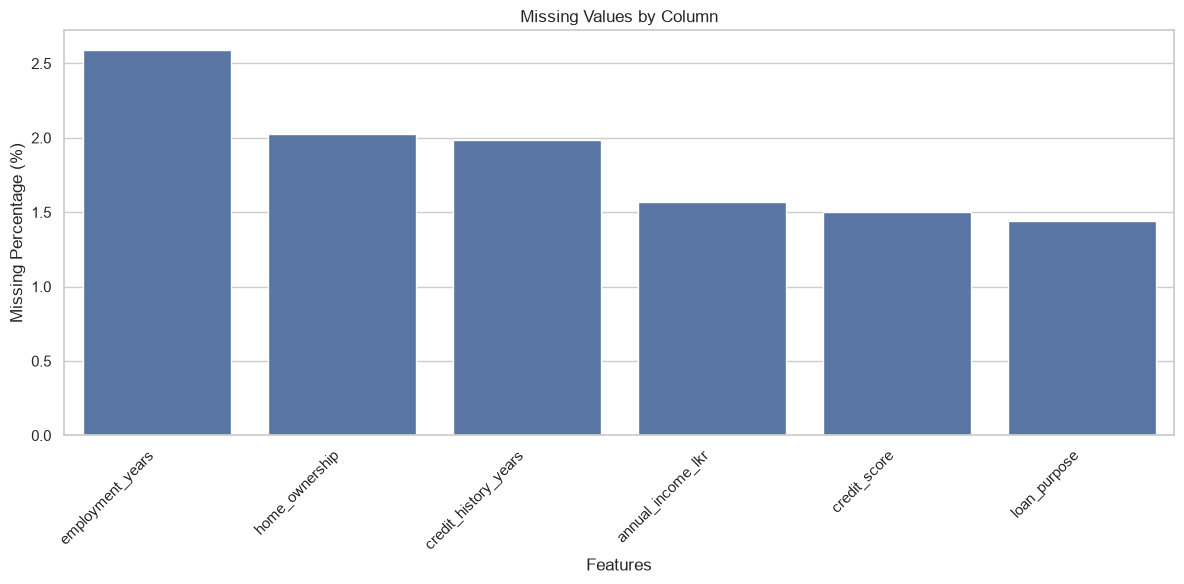

In [10]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_summary.reset_index(),
    x="index",
    y="Missing_Percentage"
)

plt.title("Missing Values by Column")
plt.xlabel("Features")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [9]:
print("COLLATERAL TYPE DISTRIBUTION")
print("=" * 40)

print(df["collateral_type"].value_counts(dropna=False))

print("\nMissing collateral values:")
print(df["collateral_type"].isnull().sum())

COLLATERAL TYPE DISTRIBUTION
collateral_type
No Collateral    40103
Property         29771
Vehicle          20138
Fixed Deposit     9988
Name: count, dtype: int64

Missing collateral values:
0


In [10]:

# Identify numerical columns

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Remove target variable
numerical_columns.remove("default_flag")

# Remove identifiers if present
numerical_columns = [
    col for col in numerical_columns
    if col not in ["loan_id", "customer_id"]
]

print("NUMERICAL FEATURES")
print("=" * 50)

for column in numerical_columns:
    print(column)

print("\nTotal numerical features:", len(numerical_columns))


NUMERICAL FEATURES
age
employment_years
annual_income_lkr
monthly_income_lkr
existing_loans
outstanding_debt_lkr
credit_score
credit_history_years
previous_defaults
delinquencies_last_2yrs
credit_utilization
loan_amount_lkr
loan_term_months
interest_rate_pct
monthly_emi_lkr
debt_to_income_ratio
collateral_value_lkr

Total numerical features: 17


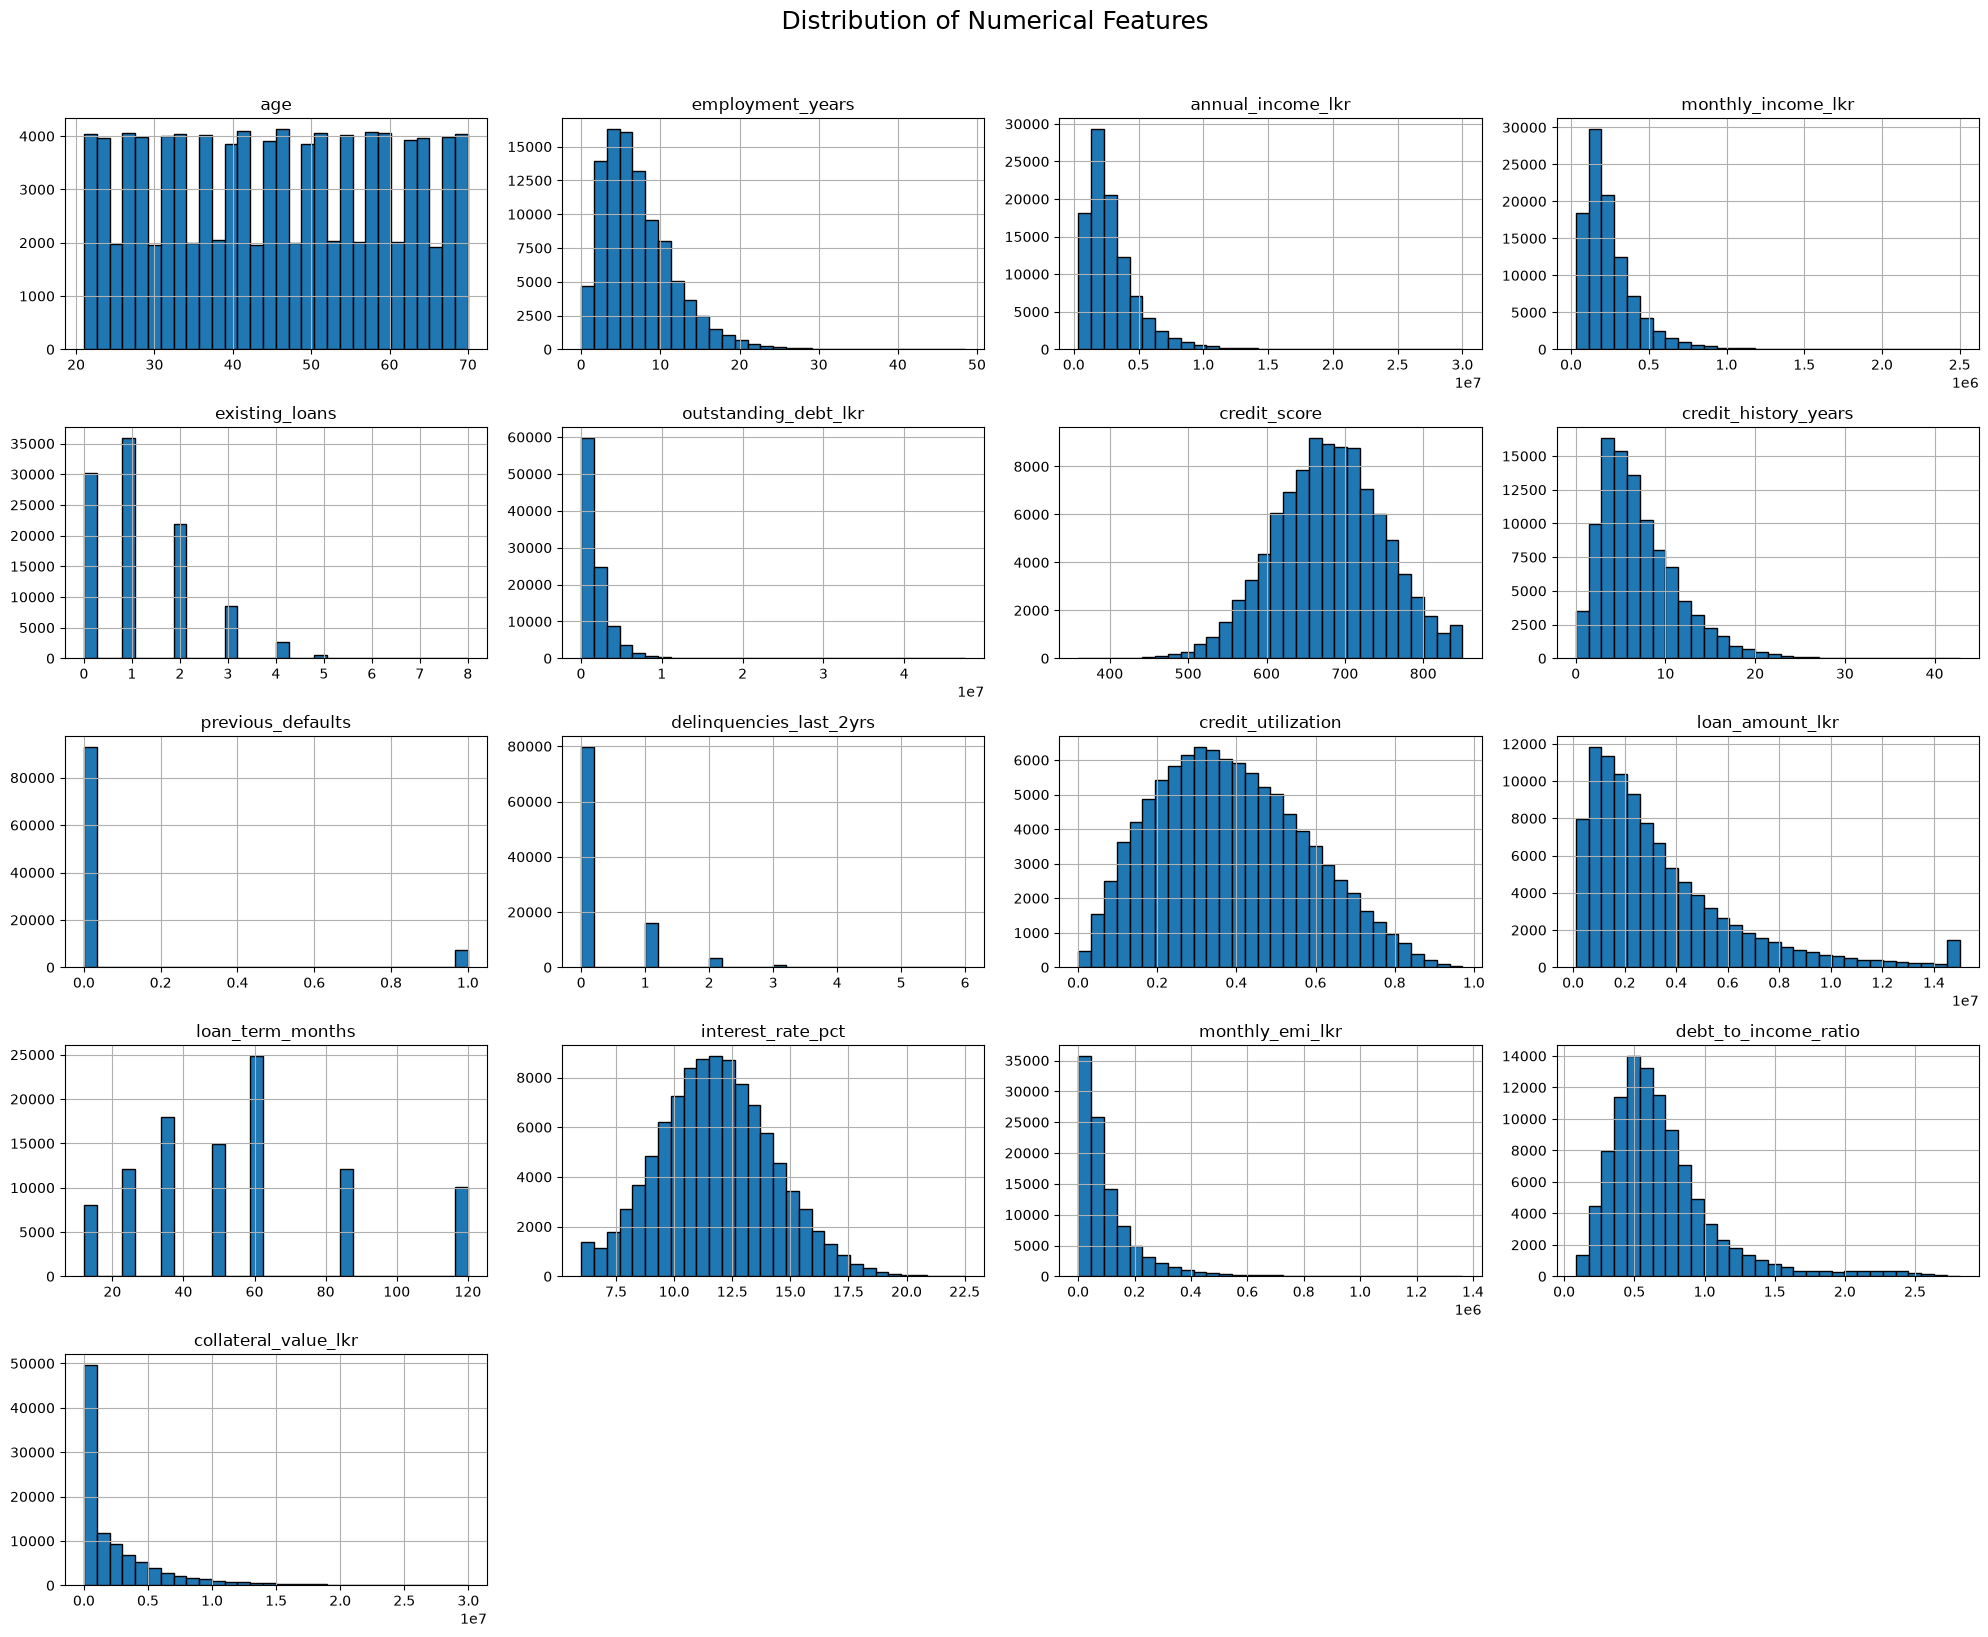

In [11]:

# Plot numerical feature distributions

df[numerical_columns].hist(
    figsize=(20, 16),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=18,
    y=1.02
)

plt.tight_layout()
plt.show()


In [12]:

# Identify categorical columns

categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

# Remove identifier columns
categorical_columns = [
    col for col in categorical_columns
    if col not in ["loan_id", "customer_id"]
]

print("CATEGORICAL FEATURES")
print("=" * 50)

for column in categorical_columns:
    print(column)

print("\nTotal categorical features:", len(categorical_columns))


CATEGORICAL FEATURES
application_date
gender
marital_status
education_level
employment_type
home_ownership
loan_purpose
has_cosigner
collateral_type

Total categorical features: 9


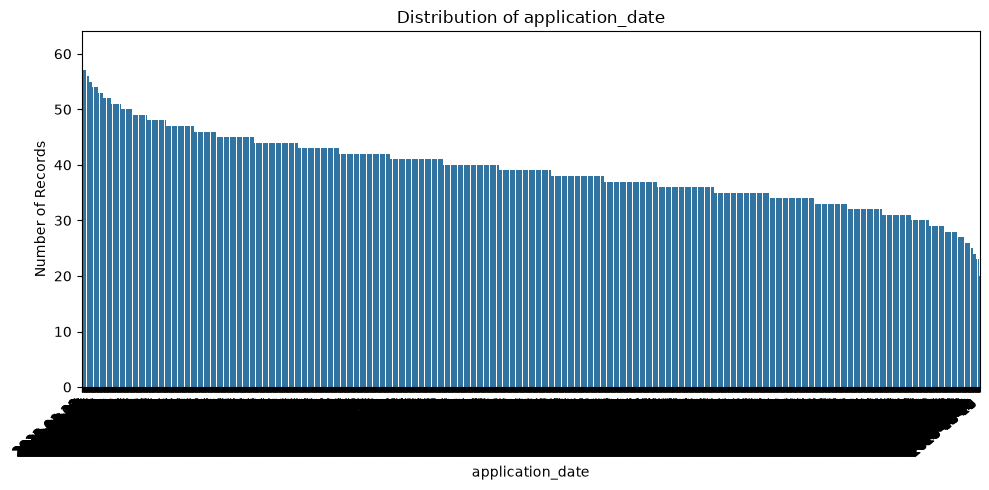

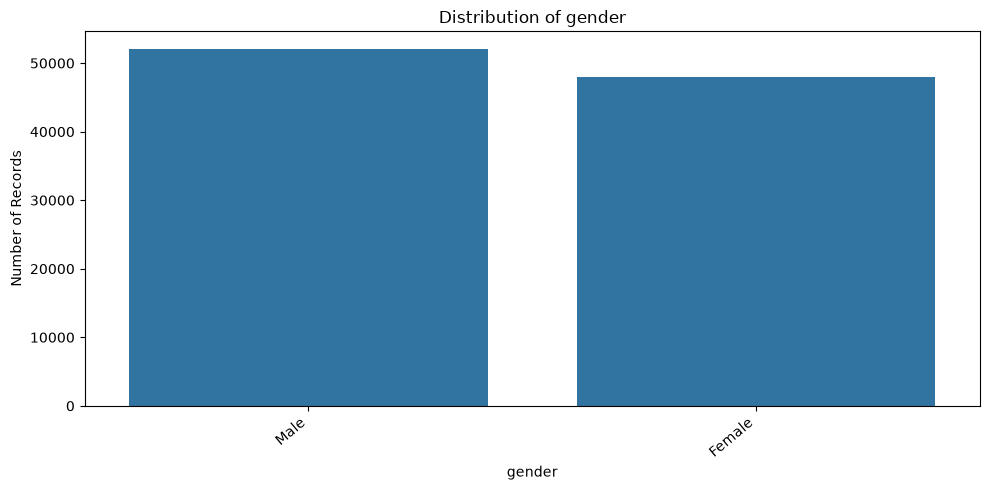

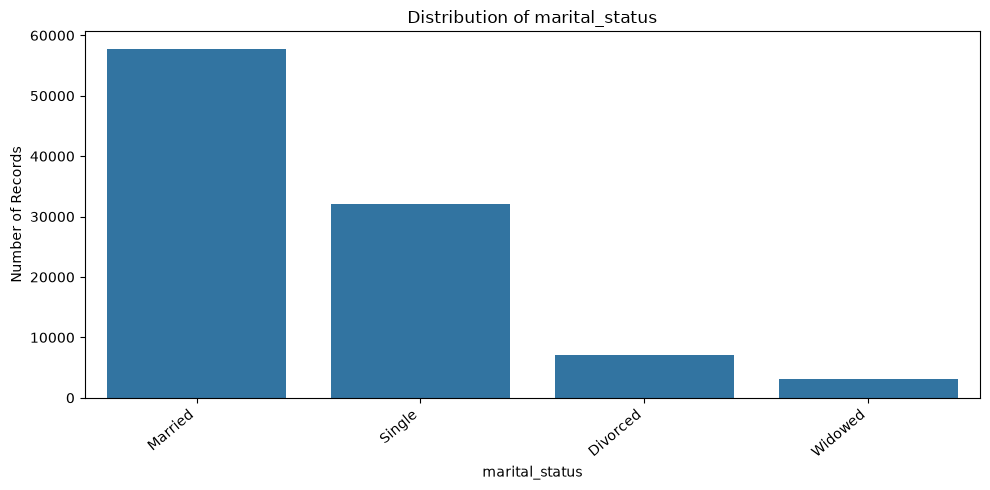

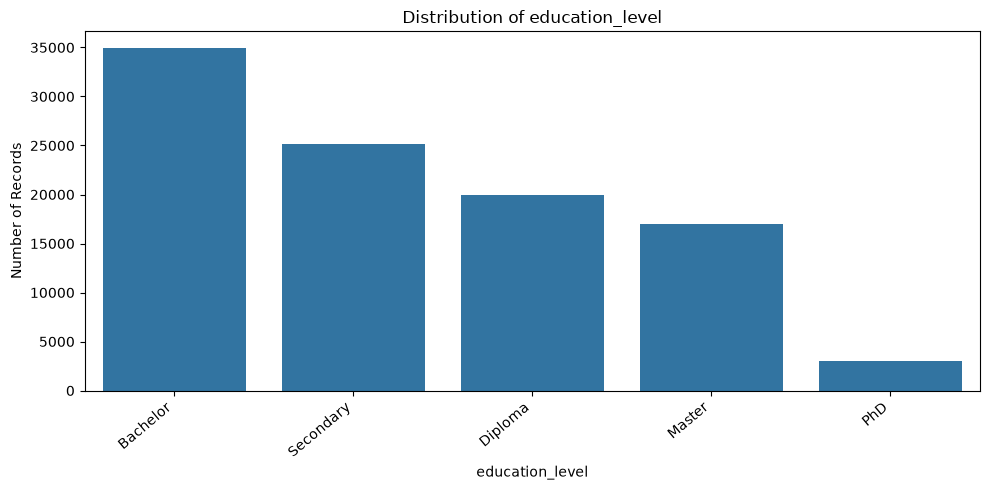

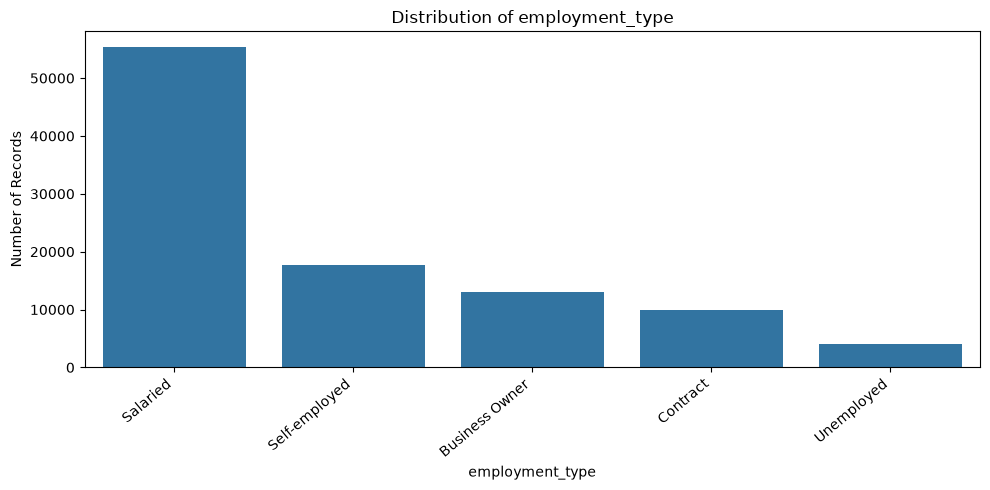

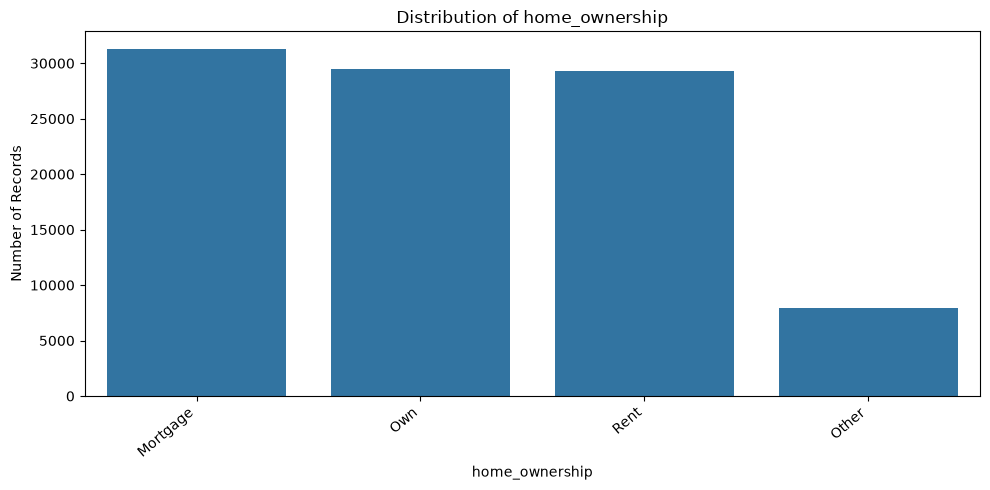

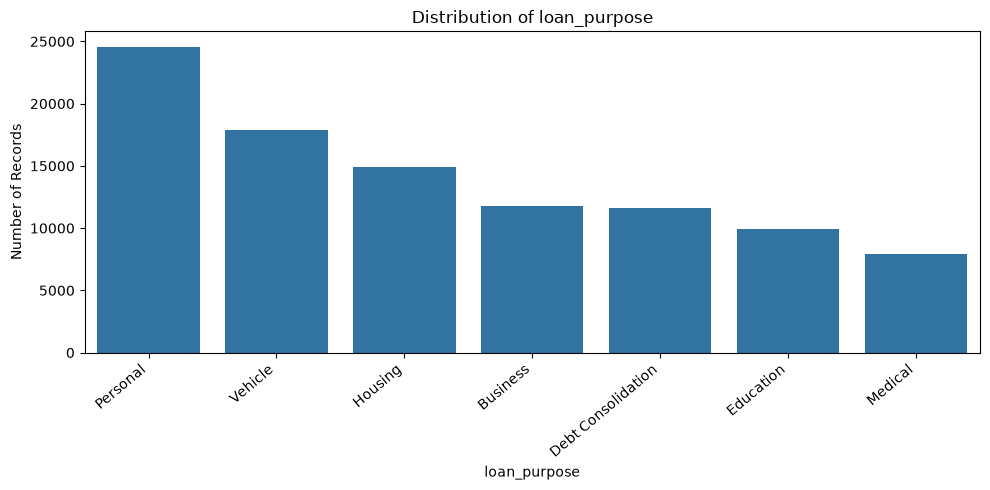

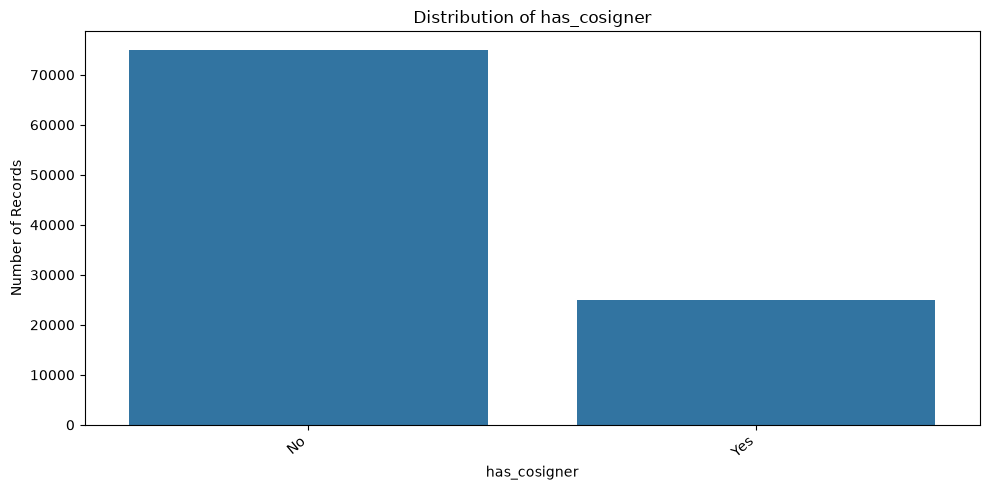

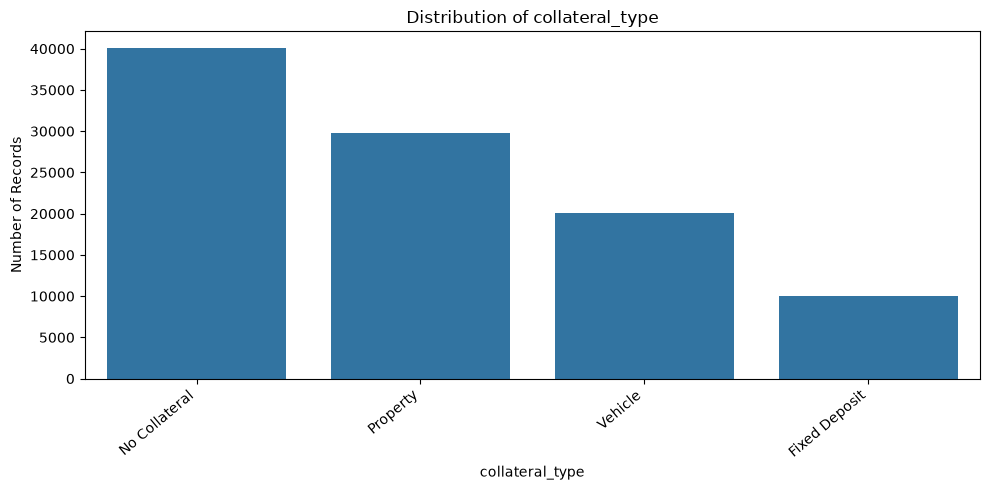

In [13]:

# Plot categorical feature distributions

for column in categorical_columns:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Records")

    plt.xticks(rotation=40, ha="right")

    plt.tight_layout()
    plt.show()


CORRELATION MATRIX


,age,employment_years,annual_income_lkr,monthly_income_lkr,existing_loans,outstanding_debt_lkr,credit_score,credit_history_years,previous_defaults,delinquencies_last_2yrs,credit_utilization,loan_amount_lkr,loan_term_months,interest_rate_pct,monthly_emi_lkr,debt_to_income_ratio,collateral_value_lkr,default_flag
age,1.000,0.161,0.003,0.003,0.000,0.003,-0.000,0.158,-0.006,0.000,-0.001,0.004,-0.003,-0.002,0.008,0.005,-0.000,0.004
employment_years,0.161,1.000,0.004,0.004,-0.003,0.002,-0.000,0.057,0.002,-0.002,-0.004,0.005,-0.002,-0.002,0.005,0.001,-0.002,-0.004
annual_income_lkr,0.003,0.004,1.000,1.000,0.003,0.704,-0.001,0.001,0.002,0.005,0.004,0.738,0.000,0.004,0.539,-0.021,0.425,-0.014
monthly_income_lkr,0.003,0.004,1.000,1.000,0.002,0.704,-0.001,0.000,0.003,0.005,0.004,0.738,0.000,0.005,0.539,-0.022,0.426,-0.014
existing_loans,0.000,-0.003,0.003,0.002,1.000,0.002,0.002,0.005,0.000,0.001,0.000,0.003,0.005,-0.001,-0.001,-0.004,0.005,-0.002
outstanding_debt_lkr,0.003,0.002,0.704,0.704,0.002,1.000,0.002,0.002,-0.003,0.004,0.009,0.515,-0.000,-0.002,0.379,0.113,0.297,0.038
credit_score,-0.000,-0.000,-0.001,-0.001,0.002,0.002,1.000,-0.004,-0.194,-0.404,0.007,0.003,-0.003,-0.738,-0.019,-0.030,0.000,-0.258
credit_history_years,0.158,0.057,0.001,0.000,0.005,0.002,-0.004,1.000,-0.001,-0.002,0.004,0.003,0.001,0.002,0.003,0.001,-0.004,0.002
previous_defaults,-0.006,0.002,0.002,0.003,0.000,-0.003,-0.194,-0.001,1.000,0.088,-0.003,0.004,0.004,0.340,0.008,0.011,0.006,0.169
delinquencies_last_2yrs,0.000,-0.002,0.005,0.005,0.001,0.004,-0.404,-0.002,0.088,1.000,-0.001,0.001,-0.002,0.303,0.013,0.015,-0.000,0.161


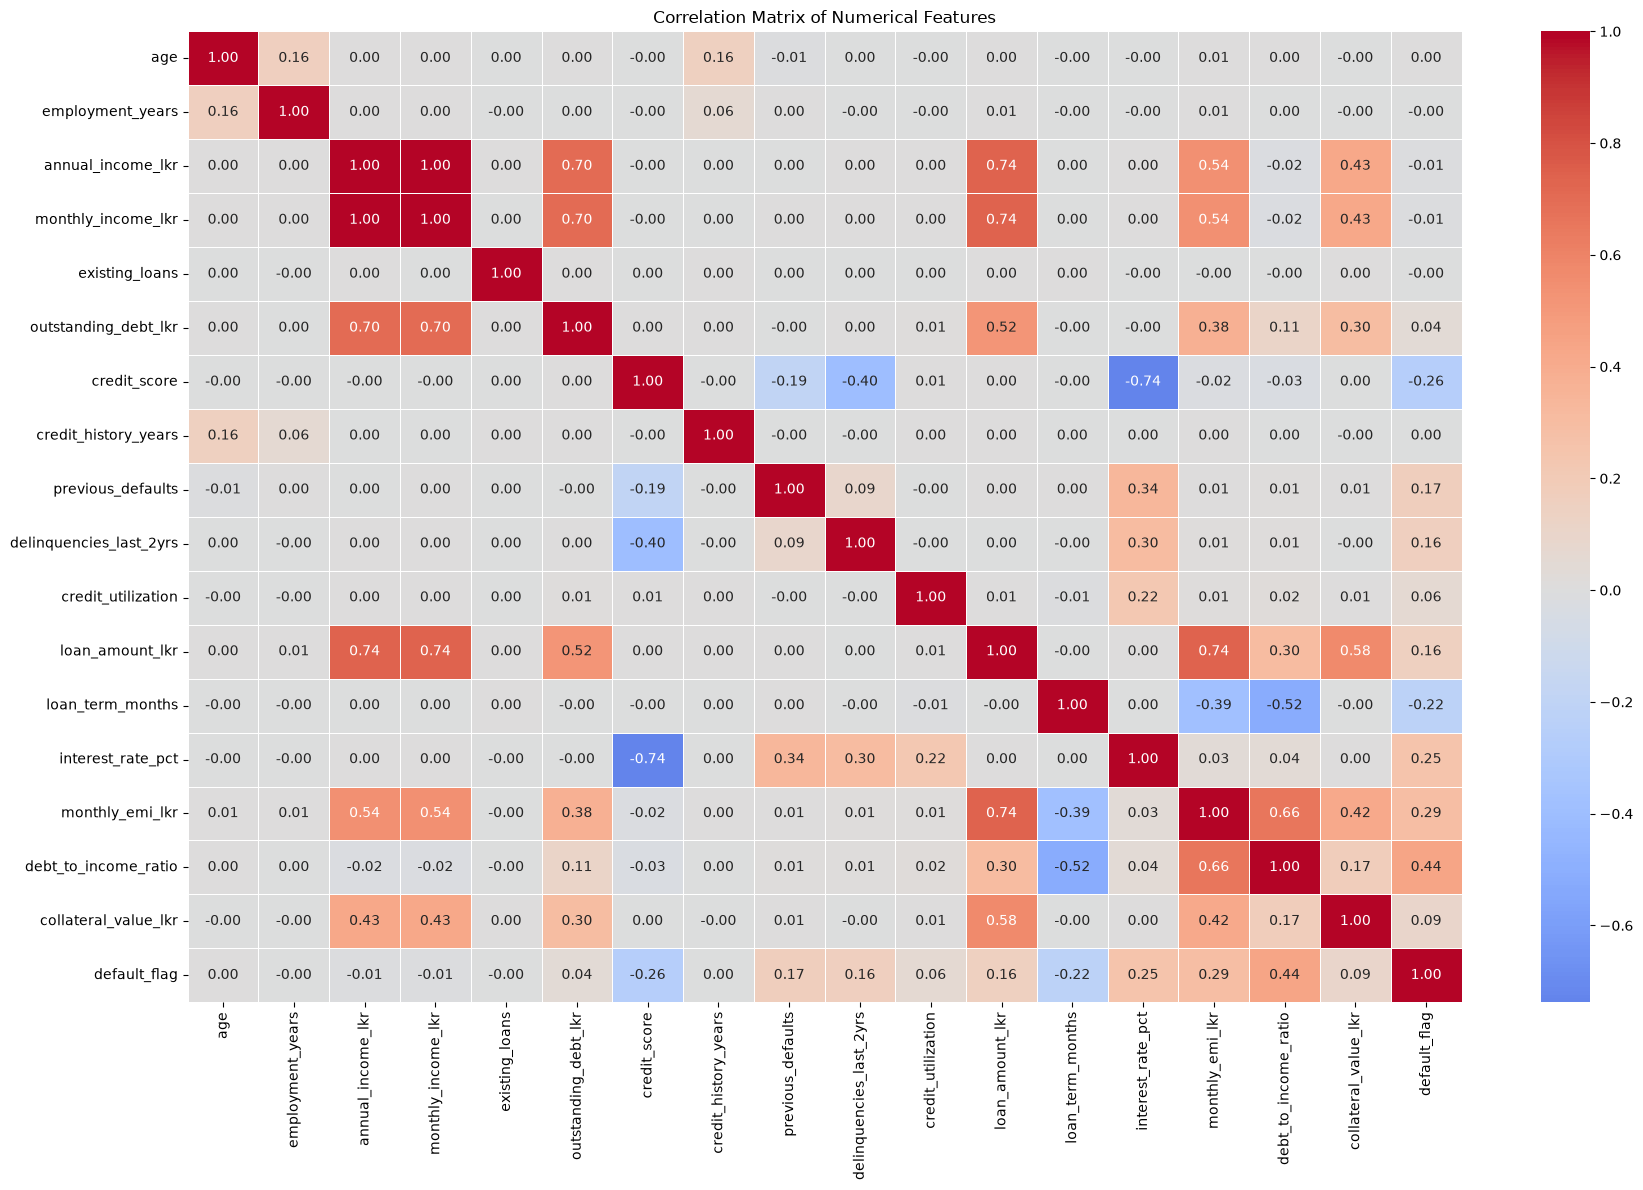

In [14]:

# Calculate numerical correlations

correlation_columns = numerical_columns + ["default_flag"]

correlation_matrix = df[
    correlation_columns
].corr()

print("CORRELATION MATRIX")
display(correlation_matrix.round(3))

# Visualize correlations

plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")

plt.tight_layout()
plt.show()


,count,mean,default_rate_pct
employment_type,,,
Unemployed,4029,0.42,42.44
Contract,9855,0.35,35.18
Business Owner,13030,0.33,33.42
Salaried,55316,0.33,33.31
Self-employed,17770,0.33,33.17


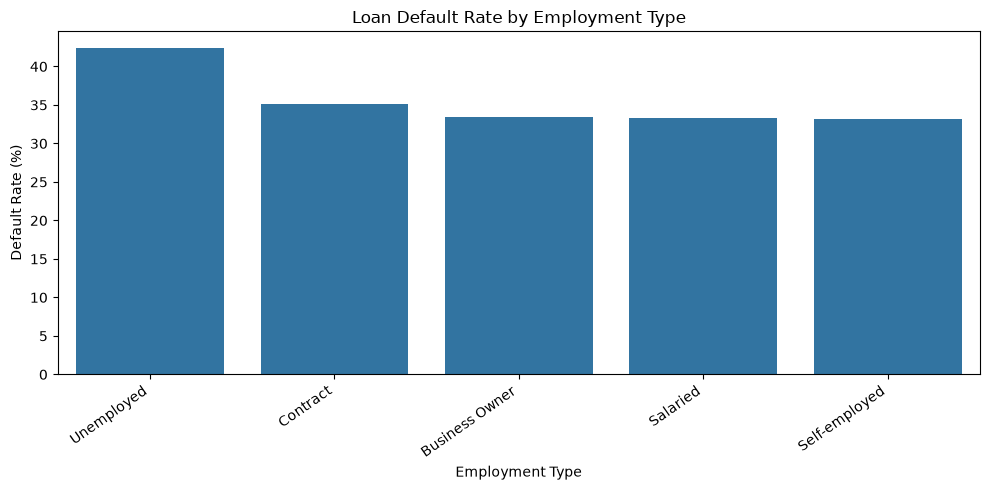

In [15]:

# Calculate default rate by employment type

employment_default = (
    df.groupby("employment_type")["default_flag"]
    .agg(["count", "mean"])
)

employment_default["default_rate_pct"] = (
    employment_default["mean"] * 100
)

employment_default = employment_default.sort_values(
    by="default_rate_pct",
    ascending=False
)

display(employment_default.round(2))

# Visualization

plt.figure(figsize=(10, 5))

sns.barplot(
    data=employment_default.reset_index(),
    x="employment_type",
    y="default_rate_pct"
)

plt.title("Loan Default Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Default Rate (%)")

plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()


,count,mean,default_rate_pct
loan_purpose,,,
Medical,7894,0.34,34.05
Business,11795,0.34,33.94
Personal,24580,0.34,33.92
Housing,14892,0.34,33.87
Vehicle,17873,0.34,33.81
Education,9903,0.34,33.76
Debt Consolidation,11623,0.34,33.50


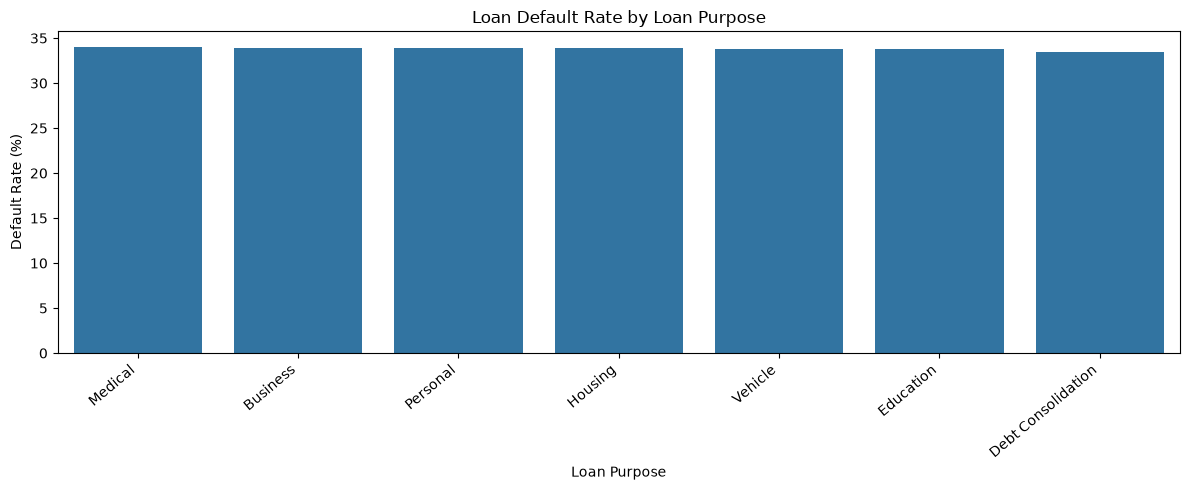

In [16]:

# Calculate default rate by loan purpose

loan_purpose_default = (
    df.groupby("loan_purpose")["default_flag"]
    .agg(["count", "mean"])
)

loan_purpose_default["default_rate_pct"] = (
    loan_purpose_default["mean"] * 100
)

loan_purpose_default = loan_purpose_default.sort_values(
    by="default_rate_pct",
    ascending=False
)

display(loan_purpose_default.round(2))

# Visualization

plt.figure(figsize=(12, 5))

sns.barplot(
    data=loan_purpose_default.reset_index(),
    x="loan_purpose",
    y="default_rate_pct"
)

plt.title("Loan Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")

plt.xticks(rotation=40, ha="right")

plt.tight_layout()
plt.show()


DEFAULT RATE BY CREDIT SCORE


credit_score_group
Poor         60.28
Fair         42.14
Good         28.00
Very Good    18.64
Name: default_flag, dtype: float64

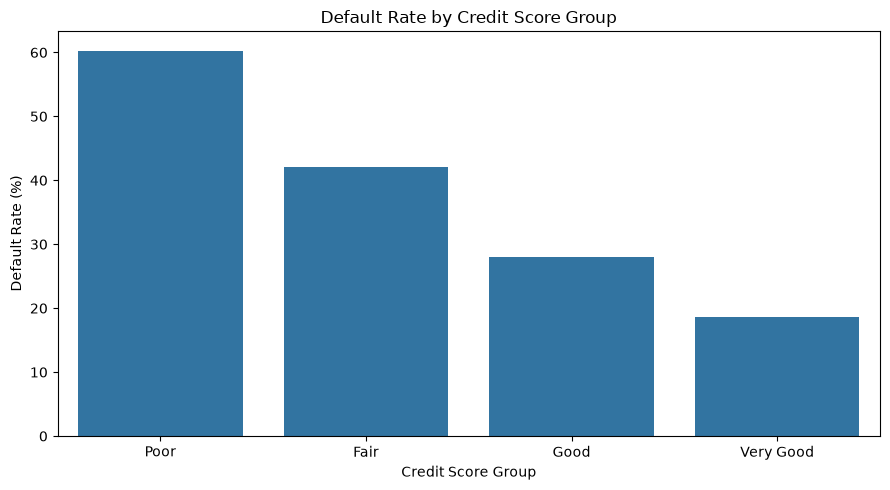

In [17]:

# Create credit score groups

credit_score_df = df.dropna(
    subset=["credit_score"]
).copy()

credit_score_df["credit_score_group"] = pd.cut(
    credit_score_df["credit_score"],
    bins=[0, 580, 670, 740, 850],
    labels=[
        "Poor",
        "Fair",
        "Good",
        "Very Good"
    ]
)

credit_default = (
    credit_score_df.groupby(
        "credit_score_group",
        observed=False
    )["default_flag"]
    .mean()
    * 100
)

print("DEFAULT RATE BY CREDIT SCORE")
display(credit_default.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    x=credit_default.index.astype(str),
    y=credit_default.values
)

plt.title("Default Rate by Credit Score Group")
plt.xlabel("Credit Score Group")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()


DEFAULT RATE BY DTI GROUP


dti_group
Below 20%     7.55
20%-35%      11.68
35%-50%      17.00
50%-75%      27.99
Above 75%    59.33
Name: default_flag, dtype: float64

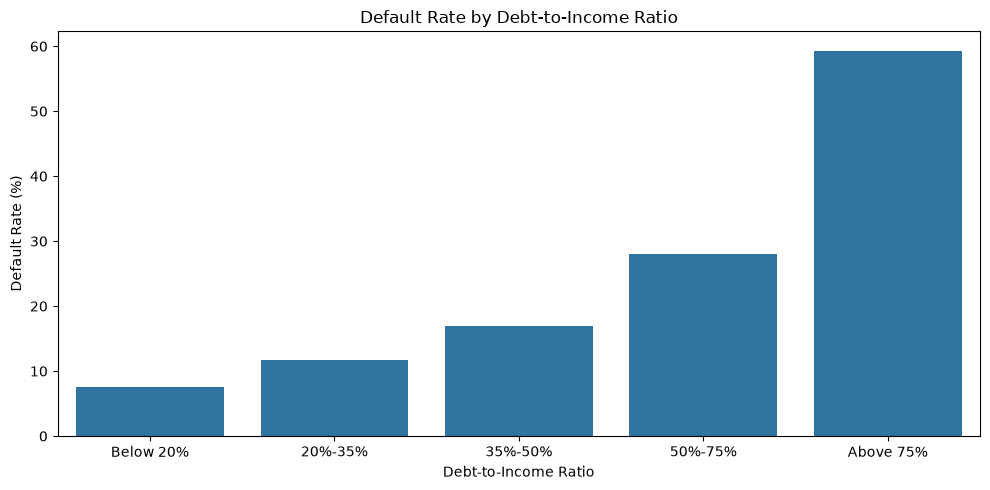

In [18]:

# Create debt-to-income ratio groups

dti_df = df.copy()

dti_df["dti_group"] = pd.cut(
    dti_df["debt_to_income_ratio"],
    bins=[-np.inf, 0.20, 0.35, 0.50, 0.75, np.inf],
    labels=[
        "Below 20%",
        "20%-35%",
        "35%-50%",
        "50%-75%",
        "Above 75%"
    ]
)

dti_default = (
    dti_df.groupby("dti_group", observed=False)["default_flag"]
    .mean()
    * 100
)

print("DEFAULT RATE BY DTI GROUP")
display(dti_default.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    x=dti_default.index.astype(str),
    y=dti_default.values
)

plt.title("Default Rate by Debt-to-Income Ratio")
plt.xlabel("Debt-to-Income Ratio")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()


In [19]:

# Calculate outliers using IQR

outlier_results = []

for column in numerical_columns:

    series = df[column].dropna()

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (series < lower_bound) |
        (series > upper_bound)
    ).sum()

    outlier_results.append({
        "Feature": column,
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": (
            outlier_count / len(series) * 100
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary = outlier_summary.sort_values(
    by="Outlier_Count",
    ascending=False
)

display(outlier_summary.round(2))


,Feature,Outlier_Count,Outlier_Percentage
9,delinquencies_last_2yrs,20386,20.39
12,loan_term_months,10023,10.02
14,monthly_emi_lkr,7377,7.38
8,previous_defaults,7190,7.19
16,collateral_value_lkr,6705,6.70
5,outstanding_debt_lkr,6169,6.17
11,loan_amount_lkr,5456,5.46
15,debt_to_income_ratio,5375,5.38
3,monthly_income_lkr,5104,5.10
2,annual_income_lkr,5032,5.11


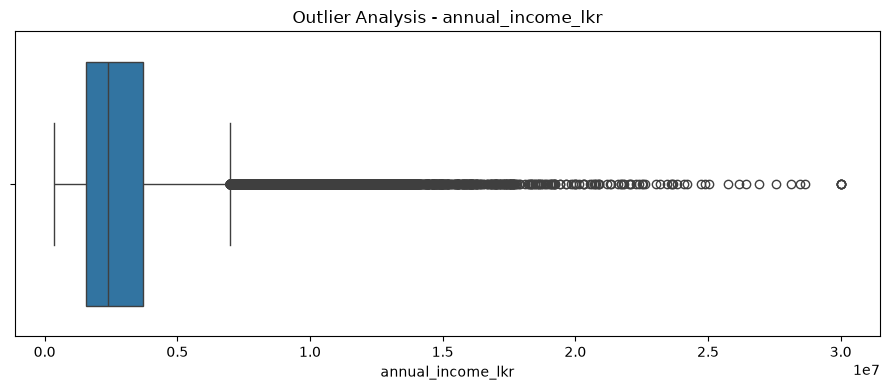

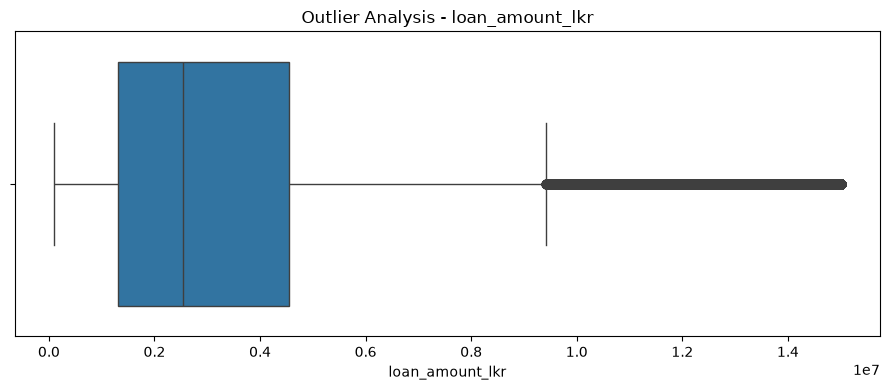

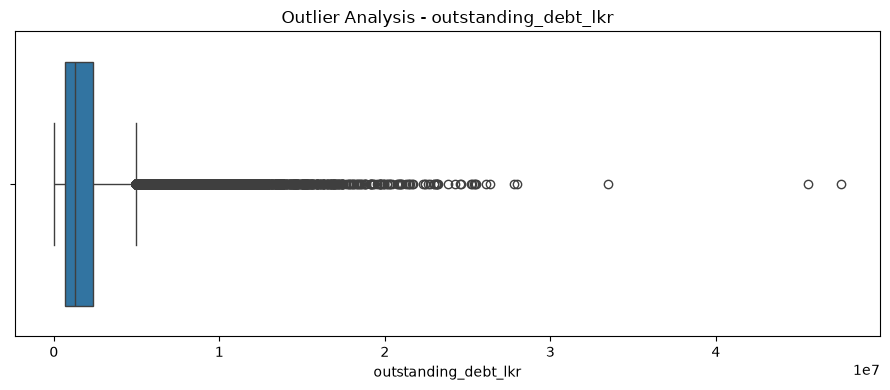

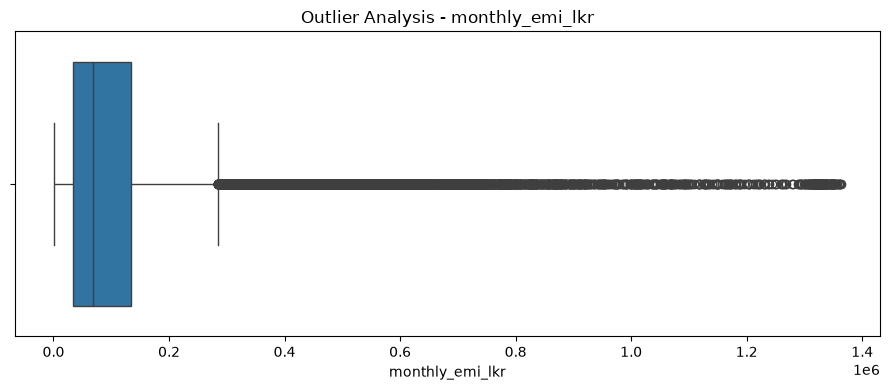

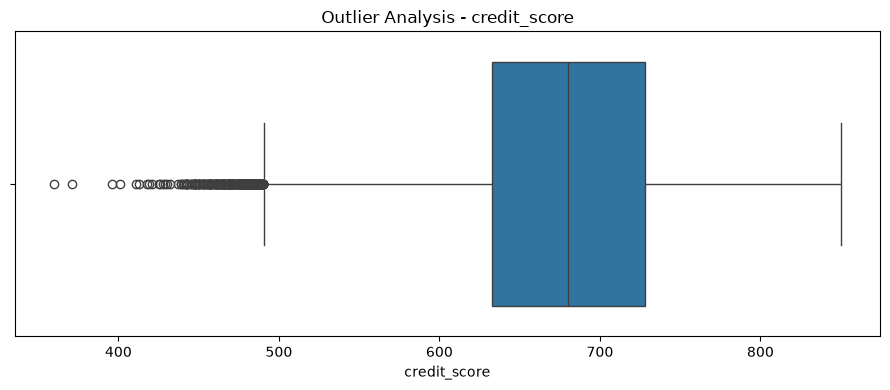

In [20]:

financial_columns = [
    "annual_income_lkr",
    "loan_amount_lkr",
    "outstanding_debt_lkr",
    "monthly_emi_lkr",
    "credit_score"
]

for column in financial_columns:

    plt.figure(figsize=(9, 4))

    sns.boxplot(x=df[column])

    plt.title(f"Outlier Analysis - {column}")
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()


,count,mean,default_rate_pct
home_ownership,,,
Mortgage,31312,0.34,33.92
Other,7897,0.34,33.63
Own,29497,0.34,33.57
Rent,29265,0.34,34.07


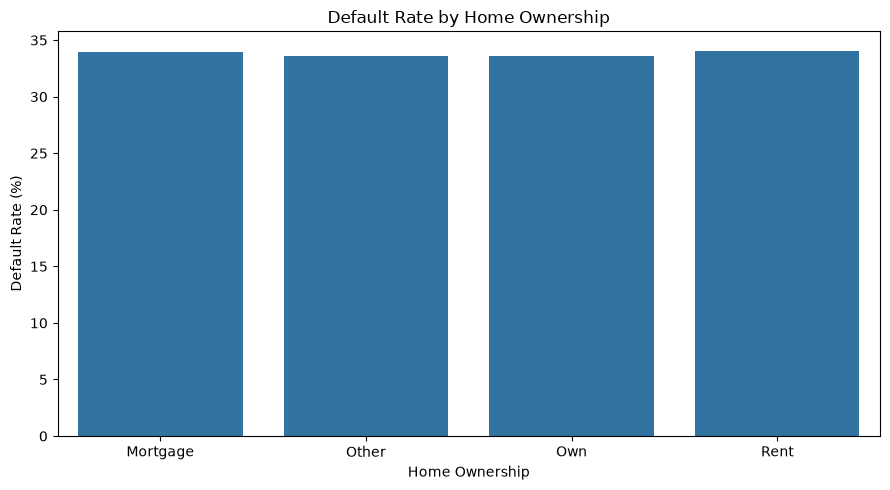

In [21]:

home_default = (
    df.groupby("home_ownership")["default_flag"]
    .agg(["count", "mean"])
)

home_default["default_rate_pct"] = (
    home_default["mean"] * 100
)

display(home_default.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=home_default.reset_index(),
    x="home_ownership",
    y="default_rate_pct"
)

plt.title("Default Rate by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()


In [23]:

from pathlib import Path
import pandas as pd

# Create reports directory
if (Path.cwd() / "data").exists():
    PROJECT_ROOT = Path.cwd()
elif (Path.cwd().parent / "data").exists():
    PROJECT_ROOT = Path.cwd().parent
else:
    raise FileNotFoundError("Project root not found!")

REPORT_DIR = PROJECT_ROOT / "artifacts" / "reports"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Recreate missing value summary
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (
        missing_values / len(df) * 100
    )
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values(
    by="Missing_Count",
    ascending=False
)

# Recreate correlation matrix
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

if "default_flag" in numerical_columns:
    numerical_columns.remove("default_flag")

correlation_matrix = df[
    numerical_columns + ["default_flag"]
].corr()

# Recreate outlier summary
outlier_results = []

for column in numerical_columns:

    series = df[column].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    count = (
        (series < lower_bound) |
        (series > upper_bound)
    ).sum()

    outlier_results.append({
        "Feature": column,
        "Outlier_Count": count,
        "Outlier_Percentage": count / len(series) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

# Recreate employment analysis
employment_default = (
    df.groupby("employment_type")["default_flag"]
    .agg(["count", "mean"])
)

employment_default["default_rate_pct"] = (
    employment_default["mean"] * 100
)

# Recreate loan purpose analysis
loan_purpose_default = (
    df.groupby("loan_purpose")["default_flag"]
    .agg(["count", "mean"])
)

loan_purpose_default["default_rate_pct"] = (
    loan_purpose_default["mean"] * 100
)

# Save all reports
missing_summary.to_csv(
    REPORT_DIR / "missing_values_report.csv"
)

correlation_matrix.to_csv(
    REPORT_DIR / "correlation_matrix.csv"
)

outlier_summary.to_csv(
    REPORT_DIR / "outlier_analysis.csv",
    index=False
)

employment_default.to_csv(
    REPORT_DIR / "default_by_employment.csv"
)

loan_purpose_default.to_csv(
    REPORT_DIR / "default_by_loan_purpose.csv"
)

print("All EDA reports saved successfully!")

print("\nSaved files:")

for file in REPORT_DIR.glob("*.csv"):
    print(file.name)

print("\nReport location:", REPORT_DIR)


All EDA reports saved successfully!

Saved files:
correlation_matrix.csv
default_by_employment.csv
default_by_loan_purpose.csv
missing_values_report.csv
outlier_analysis.csv

Report location: c:\Users\Admin\Desktop\Projects\Banking-Loan-Default-Prediction-ML\artifacts\reports
